In [1]:
import sys
import os

# Thêm thư mục gốc của dự án vào đường dẫn tìm kiếm module của Python
sys.path.append(os.path.abspath('..'))

import pandas as pd
from src.data_prep import load_and_clean_data, split_train_test

# 1. Nạp và làm sạch data
df = load_and_clean_data('../data/raw/gas_turbine_data.csv')

print("Đã import src và load data thành công!")

Đã import src và load data thành công!


In [2]:
# 2. Chia tập
X_train, y_train, X_test, y_test = split_train_test(df)

# 3. Nối X và y lại rồi tự lưu ra file trên máy
train_df = pd.concat([X_train, y_train], axis=1)
test_df = pd.concat([X_test, y_test], axis=1)

train_df.to_csv('../data/processed/train.csv', index=False)
test_df.to_csv('../data/processed/test.csv', index=False)

print("Đã tạo xong train.csv và test.csv sạch sẽ!")

Đã tạo xong train.csv và test.csv sạch sẽ!


In [3]:
from xgboost import XGBRegressor

model = XGBRegressor(random_state = 42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [4]:
y_pred

array([[  3.1729586,  77.76272  ],
       [  2.97429  ,  77.80868  ],
       [  2.7539492,  73.467064 ],
       ...,
       [  8.01801  , 107.06805  ],
       [  1.8521028,  85.64815  ],
       [  3.5917969,  89.57772  ]], shape=(14535, 2), dtype=float32)

In [5]:
from src.evaluation import evaluate_regression

results_co = evaluate_regression(y_test.iloc[:, 0], y_pred[:, 0], model_name="XGBoost Baseline - CO")
results_nox = evaluate_regression(y_test.iloc[:, 1], y_pred[:, 1], model_name="XGBoost Baseline - NOX")

=== KẾT QUẢ ĐÁNH GIÁ: XGBoost Baseline - CO ===
MSE  : 1.4230
RMSE : 1.1929
MAE  : 0.8658
R2   : 0.5708
=== KẾT QUẢ ĐÁNH GIÁ: XGBoost Baseline - NOX ===
MSE  : 174.3442
RMSE : 13.2039
MAE  : 11.4513
R2   : -0.5585


In [11]:
from sklearn.model_selection import RandomizedSearchCV
import xgboost as xgb

# 1. Tách riêng biến target cho CO và NOX
y_train_co = y_train.iloc[:, 0]
y_test_co = y_test.iloc[:, 0]

y_train_nox = y_train.iloc[:, 1]
y_test_nox = y_test.iloc[:, 1]

# 2. Định nghĩa "không gian siêu tham số" cần máy tính dò tìm

param_grid = {
    "n_estimators": [100, 200, 300, 500], 
    # Số lượng "Chuyên gia" (cây quyết định) sẽ được huy động
    'max_depth': [3, 5, 7, 9],
    # Giới hạn mỗi cây được đào sâu bao nhiêu tầng. Nếu quá sâu thì sẽ bị học vẹt
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    # Tốc độ học
    'subsample': [0.7, 0.8, 1.0],
    'colsample_bytree': [0.7, 0.8, 1.0]
}

# 3. Khởi tạo mô hình chuyên biệt cho CO
xgb_co = xgb.XGBRegressor(random_state=42)

# 4. Cấu hình cỗ máy dò tìm RandomizedSearchCV
random_search_co = RandomizedSearchCV(
    estimator=xgb_co,
    param_distributions=param_grid,
    n_iter=15,       # Bốc ngẫu nhiên 15 tổ hợp để thử nghiệm
    scoring = 'r2',  # Dùng r2 làm tiêu chí chọn
    cv=3,            # Thi thử 3 lần (Cross-Validation) cho mỗi tổ hợp
    verbose=1,       # In ra tiến trình chạy
    random_state=42, 
    n_jobs=-1        # Ép cho CPU chạy đa luồng
)

# 5. Khởi động dò tìm tham số cho CO
print("Đang chạy Tuning cho mô hình CO. Đợi chút nhé...")
random_search_co.fit(X_train, y_train_co)

# 6. In ra tổ hợp tham số xịn nhất
print("\n[BỘ THAM SỐ TỐI ƯU CHO CO]:", random_search_co.best_params_)

# 7. Dự đoán và chấm điểm lại bằng mô hình đã độ (best_estimator_)
best_model_co = random_search_co.best_estimator_
y_pred_co_tuned = best_model_co.predict(X_test)

print("\n=== KẾT QUẢ ĐÁNH GIÁ: XGBoost Tuned - CO ===")
results_co_tuned = evaluate_regression(y_test_co, y_pred_co_tuned, model_name="XGBoost Tuned - CO")

Đang chạy Tuning cho mô hình CO. Đợi chút nhé...
Fitting 3 folds for each of 15 candidates, totalling 45 fits

[BỘ THAM SỐ TỐI ƯU CHO CO]: {'subsample': 0.7, 'n_estimators': 300, 'max_depth': 5, 'learning_rate': 0.01, 'colsample_bytree': 1.0}

=== KẾT QUẢ ĐÁNH GIÁ: XGBoost Tuned - CO ===
=== KẾT QUẢ ĐÁNH GIÁ: XGBoost Tuned - CO ===
MSE  : 1.1225
RMSE : 1.0595
MAE  : 0.7546
R2   : 0.6615


In [7]:
# 1. Khởi tạo mô hình chuyên biệt cho NOX
xgb_nox = xgb.XGBRegressor(random_state=42)

# 2. Cấu hình cỗ máy dò tìm cho NOX (dùng lại param_grid đã khai báo ở trên)
random_search_nox = RandomizedSearchCV(
    estimator=xgb_nox,
    param_distributions=param_grid,
    n_iter=15,
    scoring='r2',
    cv=3,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

# 3. Khởi động dò tìm tham số cho NOX
print("Đang chạy Tuning cho mô hình NOX. Chờ kết quả nhé...")
random_search_nox.fit(X_train, y_train_nox)

# 4. In ra tổ hợp tham số xịn nhất cho NOX
print("\n[BỘ THAM SỐ TỐI ƯU CHO NOX]:", random_search_nox.best_params_)

# 5. Dự đoán và chấm điểm lại
best_model_nox = random_search_nox.best_estimator_
y_pred_nox_tuned = best_model_nox.predict(X_test)

print("\n=== KẾT QUẢ ĐÁNH GIÁ: XGBoost Tuned - NOX ===")
results_nox_tuned = evaluate_regression(y_test_nox, y_pred_nox_tuned, model_name="XGBoost Tuned - NOX")

Đang chạy Tuning cho mô hình NOX. Chờ kết quả nhé...
Fitting 3 folds for each of 15 candidates, totalling 45 fits

[BỘ THAM SỐ TỐI ƯU CHO NOX]: {'subsample': 0.8, 'n_estimators': 300, 'max_depth': 5, 'learning_rate': 0.05, 'colsample_bytree': 0.8}

=== KẾT QUẢ ĐÁNH GIÁ: XGBoost Tuned - NOX ===
=== KẾT QUẢ ĐÁNH GIÁ: XGBoost Tuned - NOX ===
MSE  : 155.2609
RMSE : 12.4604
MAE  : 11.0844
R2   : -0.3879


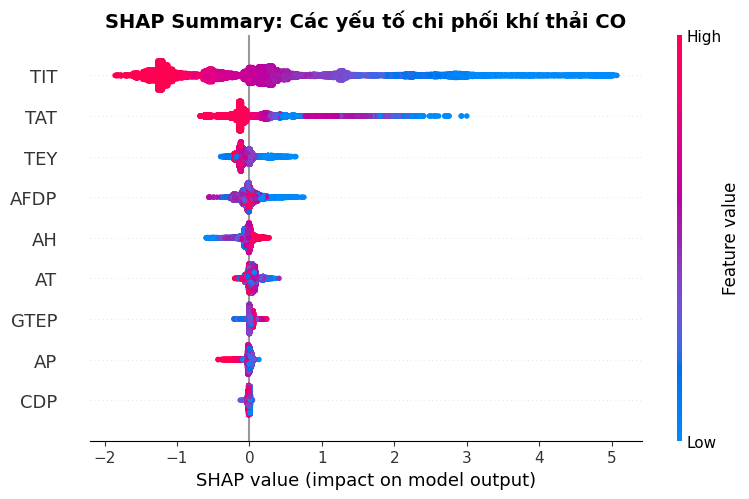

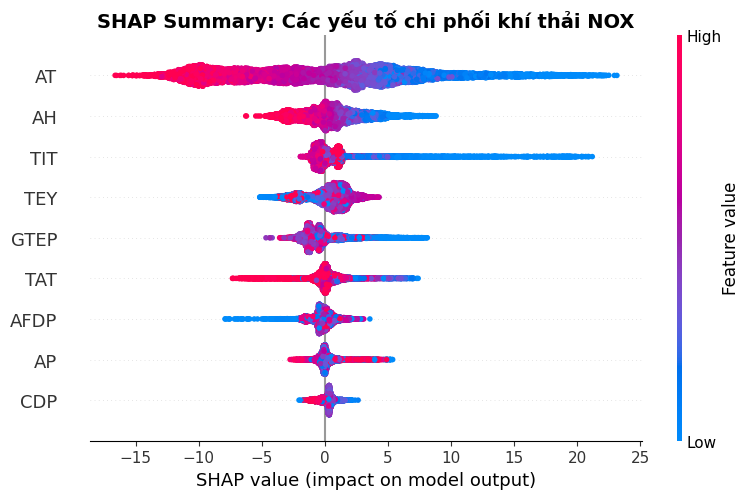

In [9]:
import shap
import matplotlib.pyplot as plt

# Khởi tạo bộ tính toán SHAP cho CO
explainer_co = shap.TreeExplainer(best_model_co)
shap_values_co = explainer_co.shap_values(X_test)

# Khởi tạo bộ tính toán SHAP cho mô hình NOX
explainer_nox = shap.TreeExplainer(best_model_nox)
shap_values_nox = explainer_nox.shap_values(X_test)

# 1. Vẽ biểu đồ Tổng quan (Summary Plot) cho Co
plt.figure(figsize=(10,6))
plt.title("SHAP Summary: Các yếu tố chi phối khí thải CO", fontsize=14, fontweight='bold')
shap.summary_plot(shap_values_co, X_test, show=False)
plt.show()

# 2. Vẽ biểu đồ Tổng quan (Summary Plot) cho NOX
plt.figure(figsize=(10,6))
plt.title("SHAP Summary: Các yếu tố chi phối khí thải NOX", fontsize=14, fontweight='bold')
shap.summary_plot(shap_values_nox, X_test, show=False)
plt.show()



In [16]:
import joblib
import os
import matplotlib.pyplot as plt
import shap

os.makedirs('../models', exist_ok=True)
os.makedirs('../reports/figures', exist_ok=True)

joblib.dump(best_model_co, '../models/xgboost_tuned_co.pkl')
joblib.dump(best_model_nox, '../models/xgboost_tuned_nox.pkl')
print('Lưu mô hình vào ../models')

# 1. Vẽ biểu đồ Tổng quan (Summary Plot) cho Co
plt.figure(figsize=(10,6))
plt.title("SHAP Summary: Các yếu tố chi phối khí thải CO", fontsize=14, fontweight='bold')
shap.summary_plot(shap_values_co, X_test, show=False)
plt.savefig('../reports/figures/shap_summary_co.png', dpi=300, bbox_inches='tight')
plt.close()

# 2. Vẽ biểu đồ Tổng quan (Summary Plot) cho NOX
plt.figure(figsize=(10,6))
plt.title("SHAP Summary: Các yếu tố chi phối khí thải NOX", fontsize=14, fontweight='bold')
shap.summary_plot(shap_values_nox, X_test, show=False)
plt.savefig('../reports/figures/shap_summary_nox.png', dpi=300, bbox_inches='tight')
plt.close()




Lưu mô hình vào ../models
